# Встреча 2. План теста — практика

**Легенда.** Встреча 1 закончилась вердиктом «тестируем»: решение по конверсии принимаем против точки безубыточности, α = 0.5, 105 тыс. пользователей, 14 дней. Теперь пишем план теста нового чекаута: что этот тест способен увидеть, честен ли критерий на наших данных, насколько сократит тест CUPED, какие метрики за что отвечают и хватает ли 14 дней guardrail. Итог — заполненный дизайн-док, с ним идём на встречу 3 (запуск).

Данные — `data/checkout_ab.csv`: одна строка — один пользователь чекаута за 14 дней, сплит 80/20, предпериод 28 дней (`orders_prev28`, `revenue_prev28`). Тест мы ещё **планируем**, поэтому для оценок берём только контроль A как «историю». Группу B не смотрим: эффект оценим на встрече 6.

**Как работать с ноутбуком**

* В ячейке задания впишите код вместо `raise NotImplementedError`.
* Под заданием — свёрнутая ячейка **«Решение»**: в Colab раскрывается кликом по заголовку, в Jupyter — по свёрнутой ячейке.
* Затем — **«Проверка»** с `assert`: зелёная ячейка значит «задание принято».
* «Run all» исполняет и решения, поэтому ноутбук всегда доходит до конца. Чтобы проверить свой код, запускайте задание и сразу проверку, пропуская решение.

| Задание | Что делаем | Минуты |
|---|---|---|
| 1 | Размер выборки и длительность: решение против θ_BE из встречи 1, сплит 80/20 и 50/50, абсолютный и относительный MDE | 12 |
| 2 | Правило решения на симуляции и A/A на своих данных (z-тест для долей) | 12 |
| 3 | CUPED на выручке: θ, снижение дисперсии, сэкономленные дни, проверка несмещённости | 15 |
| 4 | Роли метрик и поправки; хватает ли 14 дней guardrail | 10 |
| 5 | Дизайн-док | 6 |

## 0. Подготовка

In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_confint, proportion_effectsize, proportions_ztest

plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['font.size'] = 11
rng = np.random.default_rng(2026)


def sp(x) -> str:
    # Число с пробелами между разрядами: 105 000
    return f'{x:,.0f}'.replace(',', ' ')

### Параметры: всё в одном месте

`FROM_MEETING_1` — выход встречи 1. Подменили значения здесь — ниже всё пересчитается. `DESIGN` — решения, которые мы принимаем сегодня вместе с владельцем продукта.

In [2]:
# Значения — из VERDICT встречи 1
FROM_MEETING_1 = {
    'alpha': 0.5,             # OEC: одностороннее α против точки безубыточности (порог решения = BE)
    'break_even_pp': 0.246,   # θ_BE: эффект на конверсию, окупающий внедрение, п.п.
    'n_b': 21_000,            # пользователей в группе B
    'n_total': 105_000,       # пользователей в тесте
    'days': 14,
    'decision': 'тестируем',
}

DESIGN = {
    'share_b': 0.20,           # доля трафика на новый чекаут
    'daily_users': 7_500,      # плановый трафик чекаута в день (тот же, что во встрече 1)
    'power': 0.80,             # мощность OEC
    'alpha': 0.05,             # α для guardrail и вторичных метрик — классический, не из финмодели
    'mde_arpu_rel': 0.02,      # ARPU: +2% — для задания 3
    'ni_payment_error': 0.002, # guardrail: ошибки оплаты растут не более чем на 0.2 п.п. (≈10% от базы 2%)
    'min_weeks': 1,            # длительность — целые недели, не меньше одной
}

ALPHA_OEC = FROM_MEETING_1['alpha']
BE = FROM_MEETING_1['break_even_pp'] / 100
ALPHA = DESIGN['alpha']
SHARE_B, POWER, DAILY_USERS = DESIGN['share_b'], DESIGN['power'], DESIGN['daily_users']

In [3]:
DATA_PATH = Path('../data/checkout_ab.csv')
DATA_URL = 'https://raw.githubusercontent.com/Alberelloo/AITH-2026-Hypothesis-Testing-Workshop/main/data/checkout_ab.csv'
raw = pd.read_csv(DATA_PATH if DATA_PATH.exists() else DATA_URL)

# Правило очистки встречи 3 (там разберём, откуда дефекты): убрать полные дубли строк
# и целиком исключить пользователей, которые встречаются в обеих группах
df = raw.drop_duplicates()
in_both = df.groupby('user_id')['group'].nunique().loc[lambda s: s > 1].index
df = df[~df['user_id'].isin(in_both)].reset_index(drop=True)
assert len(df) == 104_960 and df['user_id'].is_unique

base = df[df['group'] == 'A'].reset_index(drop=True)   # «история»: только контроль
P_A = base['converted'].mean()

print(f"Пользователей: {sp(len(df))} (A: {sp((df['group'] == 'A').sum())}, B: {sp((df['group'] == 'B').sum())}); "
      f"в день: {sp(len(df) / df['date'].nunique())}, в плане — {sp(DAILY_USERS)}")
print(f'Конверсия контроля: {P_A:.4f}; ARPU: {sp(base["revenue"].mean())} ₽; ошибки оплаты: {base["payment_error"].mean():.4f}')
base.head()

Пользователей: 104 960 (A: 83 878, B: 21 082); в день: 7 497, в плане — 7 500
Конверсия контроля: 0.6987; ARPU: 2 604 ₽; ошибки оплаты: 0.0200


,user_id,date,group,converted,revenue,checkout_time_sec,payment_error,orders_prev28,revenue_prev28
0,7480367,2026-09-20,A,1,997.12,261.9,0,2,3817.54
1,9280410,2026-09-12,A,1,23649.07,55.2,0,7,109549.40
2,9684298,2026-09-13,A,1,2037.39,123.9,0,2,3051.12
3,1961867,2026-09-12,A,1,1761.46,45.4,0,2,2938.46
4,9825369,2026-09-09,A,1,1285.30,67.4,0,6,19640.79


## Задание 1. Размер выборки и длительность

N = 105 тыс. и 14 дней уже выбрала встреча 1. Здесь мы их **не пересчитываем**, а проверяем обратным ходом: какой эффект такой тест видит и сколько стоили бы другие решения дизайна. Хватает ли этих 14 дней остальным метрикам, решит задание 4.

Встреча 1 решила: **внедряем, если $\hat p_B - \hat p_A > \theta_{BE} = 0.246$ п.п.** Это односторонний тест против порога безубыточности, $H_0: \mu \le \theta_{BE}$, с α = 0.5: $z_{1-\alpha} = 0$, и порог решения совпадает с самой точкой безубыточности. Такой α выбрала финмодель: ошибки по обе стороны BE стоят примерно одинаково, и риск-нейтральное решение — «оценка выше BE → внедряем».

Одна формула для любой метрики со средним (для доли $\sigma^2 = p(1-p)$), $s$ — сторонность, $\mu_0$ — граница нулевой гипотезы (0 для обычного superiority, $\theta_{BE}$ для решения встречи 1):

$$
N = \frac{\left(z_{1-\alpha/s} + z_{1-\beta}\right)^2}{(\delta - \mu_0)^2}\left(\frac{\sigma_A^2}{w_A} + \frac{\sigma_B^2}{w_B}\right), \qquad w_B = \texttt{share\_b},\ w_A = 1 - w_B .
$$

Реализуйте:

* `n_total(var_a, var_b, mde, null, share_b, alpha, power, sides)` — **общий** размер выборки (обе группы), округлённый вверх;
* `duration(n, daily_users, min_weeks)` — пара `(дней, недель)`: дни — вверх до целого, недели — вверх до целого и не меньше `min_weeks`.

In [4]:
def n_total(var_a: float, var_b: float, mde: float, null: float = 0.0, share_b: float = SHARE_B,
            alpha: float = ALPHA, power: float = POWER, sides: int = 2) -> int:
    # ВАШ КОД
    raise NotImplementedError


def duration(n: int, daily_users: float = DAILY_USERS, min_weeks: int = DESIGN['min_weeks']) -> tuple[int, int]:
    # ВАШ КОД
    raise NotImplementedError

In [5]:
# @title Решение (нажмите, чтобы раскрыть)
def n_total(var_a: float, var_b: float, mde: float, null: float = 0.0, share_b: float = SHARE_B,
            alpha: float = ALPHA, power: float = POWER, sides: int = 2) -> int:
    z = stats.norm.ppf(1 - alpha / sides) + stats.norm.ppf(power)
    return math.ceil(z ** 2 / (mde - null) ** 2 * (var_a / (1 - share_b) + var_b / share_b))


def duration(n: int, daily_users: float = DAILY_USERS, min_weeks: int = DESIGN['min_weeks']) -> tuple[int, int]:
    days = math.ceil(n / daily_users)
    return days, max(min_weeks, math.ceil(days / 7))

In [6]:
# Проверка
def var_prop(p):
    return p * (1 - p)


# Классический случай сверяем со statsmodels (он считает через эффект Коэна h — совпадение близкое, не точное)
N_STD = n_total(var_prop(P_A), var_prop(P_A + 0.01), 0.01)
n_a_sm = NormalIndPower().solve_power(effect_size=proportion_effectsize(P_A + 0.01, P_A), alpha=0.05,
                                      power=0.8, ratio=SHARE_B / (1 - SHARE_B), alternative='two-sided')
assert abs(N_STD / (n_a_sm / (1 - SHARE_B)) - 1) < 0.02, 'Расхождение со statsmodels больше 2%'
assert n_total(1, 1, 0.1, share_b=0.5, alpha=0.05, power=0.8, sides=2) == 3140, 'Проверьте формулу'
assert n_total(1, 1, 0.3, null=0.2, share_b=0.5, alpha=0.05, power=0.8, sides=2) == 3140, 'Эффект считается от границы null'
assert n_total(1, 1, 0.1, share_b=0.5, alpha=0.5, power=0.8, sides=1) == math.ceil(stats.norm.ppf(0.8) ** 2 * 400)
assert duration(7_000, 7_500, 1) == (1, 1) and duration(105_100, 7_500, 1) == (15, 3) and duration(10, 7_500, 2) == (1, 2)

# Обратная задача: какой эффект тест встречи 1 видит с мощностью 80%?
N1 = FROM_MEETING_1['n_total']
SE1 = math.sqrt(var_prop(P_A) * (1 / ((1 - SHARE_B) * N1) + 1 / (SHARE_B * N1)))
MDE = BE + (stats.norm.ppf(1 - ALPHA_OEC) + stats.norm.ppf(POWER)) * SE1
N_OEC = n_total(var_prop(P_A), var_prop(P_A + MDE), MDE, null=BE, alpha=ALPHA_OEC, sides=1)
OEC_DAYS, OEC_WEEKS = duration(N_OEC)
print(f'SE разности при N = {sp(N1)}: {100 * SE1:.3f} п.п.; MDE (мощность 80%) = {100 * MDE:.3f} п.п.')
print(f'Обратный ход: N = {sp(N_OEC)}, n_B = {sp(N_OEC * SHARE_B)}, {OEC_DAYS} дней; встреча 1: n_B = {sp(FROM_MEETING_1["n_b"])}, {FROM_MEETING_1["days"]} дней')
assert abs(N_OEC * SHARE_B / FROM_MEETING_1['n_b'] - 1) < 0.02 and OEC_DAYS == FROM_MEETING_1['days']

SE разности при N = 105 000: 0.354 п.п.; MDE (мощность 80%) = 0.544 п.п.
Обратный ход: N = 104 126, n_B = 20 825, 14 дней; встреча 1: n_B = 21 000, 14 дней


Тест встречи 1 с мощностью 80% видит эффект ≈ 0.54 п.п.: $0.246 + (0 + 0.84)\cdot 0.354$. Теперь цена решений дизайна: меняем по одному параметру. Дни округляем до недель: в будни и выходные покупают разные люди.

In [7]:
variants = {
    'встреча 1: против θ_BE, α = 0.5, односторонний': dict(mde=MDE, null=BE, alpha=ALPHA_OEC, sides=1),
    'то же, сплит 50/50': dict(mde=MDE, null=BE, alpha=ALPHA_OEC, sides=1, share_b=0.5),
    'стандарт: против 0, α = 0.05, двусторонний, тот же MDE': dict(mde=MDE),
    'стандарт, MDE +1 п.п.': dict(mde=0.01),
    'стандарт, относительный MDE +1% от P_A': dict(mde=0.01 * P_A),
}
rows = []
for name, params in variants.items():
    mde = params['mde']
    n = n_total(var_prop(P_A), var_prop(P_A + mde), **params)
    days, weeks = duration(n)
    rows.append({'вариант': name, 'MDE, п.п.': round(100 * mde, 3), 'N': n,
                 'n_B': round(n * params.get('share_b', SHARE_B)), 'дней': days, 'недель': weeks})
design_table = pd.DataFrame(rows).set_index('вариант')
design_table

,"MDE, п.п.",N,n_B,дней,недель
вариант,,,,,
"встреча 1: против θ_BE, α = 0.5, односторонний",0.544,104126,20825,14,2
"то же, сплит 50/50",0.544,66851,33426,9,2
"стандарт: против 0, α = 0.05, двусторонний, тот же MDE",0.544,346163,69233,47,7
"стандарт, MDE +1 п.п.",1.000,101679,20336,14,2
"стандарт, относительный MDE +1% от P_A",0.699,209302,41860,28,4


In [8]:
# Проверка
names = list(design_table.index)
ratio_split = design_table.loc[names[0], 'N'] / design_table.loc[names[1], 'N']
ratio_std = design_table.loc[names[2], 'N'] / design_table.loc[names[0], 'N']
ratio_rel = design_table.loc[names[4], 'N'] / design_table.loc[names[3], 'N']
assert 1.45 < ratio_split < 1.65, ratio_split
assert ratio_std > 3, ratio_std
assert 1.9 < ratio_rel < 2.2, ratio_rel
assert OEC_WEEKS == 2
print(f'80/20 дороже 50/50 в {ratio_split:.2f} раза; стандартный тест на тот же MDE дороже в {ratio_std:.1f} раза; '
      f'относительный MDE дороже абсолютного в {ratio_rel:.2f} раза')

80/20 дороже 50/50 в 1.56 раза; стандартный тест на тот же MDE дороже в 3.3 раза; относительный MDE дороже абсолютного в 2.06 раза


**Вопросы.**

1. Почему тест встречи 1 втрое дешевле «стандартного» на тот же MDE? Это не обман?
2. Чему равен α этого правила, если считать его против нуля?
3. Почему для guardrail мы не берём α = 0.5?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

1. Стандарт требует, чтобы эффект отстоял от **нуля** на $z_{0.975} + z_{0.8} \approx 2.8$ SE. Встреча 1 требует, чтобы он отстоял от **θ_BE** на $z_{0.5} + z_{0.8} \approx 0.84$ SE. Это другой вопрос: не «есть ли эффект», а «окупится ли внедрение». Финмодель встречи 1 посчитала, что ошибка «внедрили при эффекте чуть ниже BE» стоит немного, а лишние недели теста — дорого.
2. При истинном эффекте 0 правило внедряет, если $\hat p_B - \hat p_A > 0.246$ п.п., то есть $z > 0.246 / 0.354 \approx 0.69$: одностороннее α ≈ 0.24. Это осознанный выбор: внедрить нейтральное изменение дёшево.
3. α = 0.5 оправдан финмоделью для OEC, где цена ошибок в деньгах симметрична около BE. У guardrail финмодели нет: рост ошибок оплаты бьёт по репутации и поддержке, и это не отбивается конверсией. Поэтому для guardrail — классическая защита: non-inferiority, одностороннее α = 0.05, мощность с поправкой на число guardrail (задание 4).
</details>

**Итог задания 1:** OEC — односторонний z-тест против θ_BE = 0.246 п.п. с α = 0.5; MDE при мощности 0.8 ≈ 0.54 п.п.; сплит 80/20, N ≈ 105 тыс., **14 дней = 2 недели**.

## Задание 2. Правило решения на симуляции и A/A на своих данных

Формула $N$ опирается на нормальную аппроксимацию. Проверим на симуляциях, что правило встречи 1 с нашими $N$ и сплитом ведёт себя так, как задумано: при эффекте 0 внедряет в ≈ 24% случаев, при эффекте = θ_BE — в 50%, при эффекте = MDE — в 80%. Число конверсий в группе — $\mathrm{Binomial}(n_g, p_g)$, так что тысячи тестов считаются мгновенно.

$$
z = \frac{\hat p_B - \hat p_A - \mu_0}{SE}, \qquad
SE = \begin{cases}
\sqrt{\hat p(1 - \hat p)\left(\frac{1}{n_A} + \frac{1}{n_B}\right)},\ \hat p = \frac{x_A + x_B}{n_A + n_B}, & \mu_0 = 0,\\[4pt]
\sqrt{\frac{\hat p_A(1-\hat p_A)}{n_A} + \frac{\hat p_B(1-\hat p_B)}{n_B}}, & \mu_0 \ne 0.
\end{cases}
$$

При $\mu_0 = 0$ доли под $H_0$ равны, и дисперсию оцениваем по объединённой доле; при $\mu_0 \ne 0$ — нет.

Реализуйте `z_test_props(x_a, n_a, x_b, n_b, null=0.0, sides=2)` → `(z, p_value)`. Функция должна работать **с массивами**, без циклов. При `sides=1` p-value — для альтернативы $p_B - p_A > \mu_0$.

In [9]:
def z_test_props(x_a, n_a, x_b, n_b, null: float = 0.0, sides: int = 2):
    # ВАШ КОД
    raise NotImplementedError

In [10]:
# @title Решение (нажмите, чтобы раскрыть)
def z_test_props(x_a, n_a, x_b, n_b, null: float = 0.0, sides: int = 2):
    x_a, n_a, x_b, n_b = (np.asarray(v, float) for v in (x_a, n_a, x_b, n_b))
    p_a, p_b = x_a / n_a, x_b / n_b
    if null == 0:
        p_pool = (x_a + x_b) / (n_a + n_b)
        se = np.sqrt(p_pool * (1 - p_pool) * (1 / n_a + 1 / n_b))
    else:
        se = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)
    z = (p_b - p_a - null) / se
    p_value = 2 * stats.norm.sf(np.abs(z)) if sides == 2 else stats.norm.sf(z)
    return z, p_value

эффект 0       доля «внедряем» 0.2458  95% ДИ [0.2399, 0.2518]  (ожидаем 0.244)
эффект = θ_BE  доля «внедряем» 0.4993  95% ДИ [0.4924, 0.5062]  (ожидаем 0.500)
эффект = MDE   доля «внедряем» 0.8025  95% ДИ [0.7969, 0.8080]  (ожидаем 0.800)


Классический A/A, α = 0.05: 0.0495


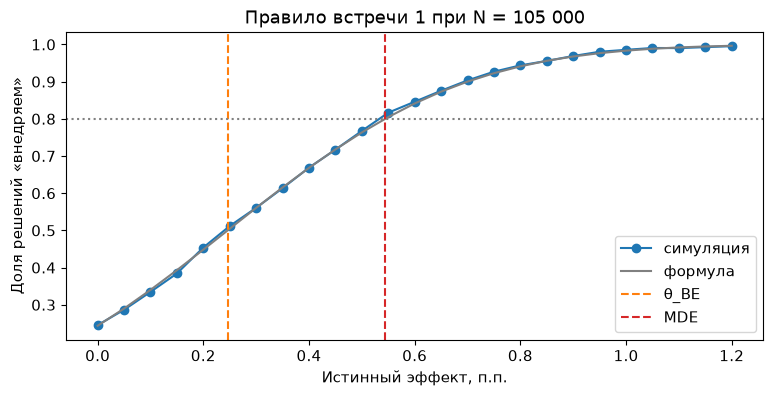

In [11]:
# Проверка
z, p = z_test_props(700, 1000, 330, 450)
z_sm, p_sm = proportions_ztest([330, 700], [450, 1000])
assert np.isclose(z, z_sm) and np.isclose(p, p_sm), 'Не совпадает со statsmodels'
assert np.isclose(z_test_props(700, 1000, 330, 450, sides=1)[1], p_sm / 2)
z_be, _ = z_test_props(700, 1000, 330, 450, null=0.01, sides=1)
assert np.isclose(z_be, (330 / 450 - 0.7 - 0.01) / np.sqrt(0.7 * 0.3 / 1000 + (330 / 450) * (1 - 330 / 450) / 450))
assert z_test_props(np.array([700, 710]), 1000, np.array([330, 330]), 450)[1].shape == (2,)

R = 20_000
n_b = FROM_MEETING_1['n_b']
n_a = FROM_MEETING_1['n_total'] - n_b


def rollout_rate(effect: float, R: int = R) -> float:
    # Доля симуляций, где правило встречи 1 говорит «внедряем»
    x_a, x_b = rng.binomial(n_a, P_A, R), rng.binomial(n_b, P_A + effect, R)
    return (z_test_props(x_a, n_a, x_b, n_b, null=BE, sides=1)[1] < ALPHA_OEC).mean()


checks = {'эффект 0': (0.0, stats.norm.sf(BE / SE1)), 'эффект = θ_BE': (BE, 0.5), 'эффект = MDE': (MDE, POWER)}
RATES = {}
for name, (effect, target) in checks.items():
    RATES[name] = rollout_rate(effect)
    lo, hi = proportion_confint(RATES[name] * R, R, method='wilson')
    print(f'{name:<14} доля «внедряем» {RATES[name]:.4f}  95% ДИ [{lo:.4f}, {hi:.4f}]  (ожидаем {target:.3f})')
    assert abs(RATES[name] - target) < 0.015, name

# Классический A/A: двусторонний тест против 0 на тех же N держит α = 0.05
p_aa = z_test_props(rng.binomial(n_a, P_A, R), n_a, rng.binomial(n_b, P_A, R), n_b)[1]
print(f'Классический A/A, α = {ALPHA}: {(p_aa < ALPHA).mean():.4f}')
assert abs((p_aa < ALPHA).mean() - ALPHA) < 0.006

effects = np.linspace(0, 0.012, 25)
plt.figure(figsize=(9, 4))
plt.plot(effects * 100, [rollout_rate(d, 5_000) for d in effects], 'o-', label='симуляция')
plt.plot(effects * 100, stats.norm.cdf((effects - BE) / SE1), color='gray', label='формула')
plt.axvline(BE * 100, color='tab:orange', ls='--', label='θ_BE')
plt.axvline(MDE * 100, color='tab:red', ls='--', label='MDE')
plt.axhline(POWER, color='gray', ls=':')
plt.xlabel('Истинный эффект, п.п.')
plt.ylabel('Доля решений «внедряем»')
plt.title(f'Правило встречи 1 при N = {sp(FROM_MEETING_1["n_total"])}')
plt.legend()
plt.show()

Биномиальная симуляция проверяет формулу, но не наши данные. **A/A на своих данных:** много раз случайно делим контроль 80/20 и прогоняем тот же z-тест. Эффекта нет по построению, поэтому классический тест должен ошибаться в ≈ 5% случаев, а правило встречи 1 — «внедрять» с той долей, которую предсказывает формула для этого $N$.

In [12]:
conv = base['converted'].to_numpy()
R_AA = 2_000
p_classic, p_rule = np.empty(R_AA), np.empty(R_AA)
for r in range(R_AA):
    is_b = rng.random(conv.size) < SHARE_B
    args = (conv[~is_b].sum(), (~is_b).sum(), conv[is_b].sum(), is_b.sum())
    p_classic[r] = z_test_props(*args)[1]
    p_rule[r] = z_test_props(*args, null=BE, sides=1)[1]
se_real = math.sqrt(var_prop(P_A) * (1 / ((1 - SHARE_B) * conv.size) + 1 / (SHARE_B * conv.size)))
ALPHA_REAL, RULE_REAL, RULE_EXPECTED = (p_classic < ALPHA).mean(), (p_rule < ALPHA_OEC).mean(), stats.norm.sf(BE / se_real)
print(f'A/A на контроле ({sp(conv.size)} польз.): классический тест {ALPHA_REAL:.3f} (ожидаем {ALPHA}); '
      f'правило встречи 1 {RULE_REAL:.3f} (ожидаем {RULE_EXPECTED:.3f})')
assert 0.035 < ALPHA_REAL < 0.065
assert abs(RULE_REAL - RULE_EXPECTED) < 0.03

A/A на контроле (83 878 польз.): классический тест 0.046 (ожидаем 0.05); правило встречи 1 0.256 (ожидаем 0.267)


**Вопросы.**

1. Почему в A/A p-value классического теста распределены равномерно и что значил бы «горб» у нуля?
2. Правило встречи 1 внедряет нейтральное изменение в каждом четвёртом тесте. Почему это не провал дизайна?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

1. Если $H_0$ верна и статистика распределена так, как мы предполагаем, то $P(p \le t) = t$ для любого $t$ — это равномерное распределение. «Горб» у нуля — критерий завышает ошибку I рода (например, считаем по заказам, а рандомизируем пользователей). «Провал» у нуля — критерий консервативен и теряет мощность.
2. Потому что дизайн отвечает на вопрос о деньгах, а не о существовании эффекта. Внедрение нейтрального изменения стоит затрат на внедрение — их финмодель уже учла, когда выбирала α. А guardrail страхует от реального вреда отдельно (задание 4). Цена — в отчёте нельзя писать «эффект доказан»: пишем «оценка выше точки безубыточности».
</details>

## Задание 3. CUPED на выручке

Финансы спрашивают: «А если решать по деньгам — ARPU, выручке на пользователя?» Забегая вперёд: в задании 4 ARPU станет диагностической метрикой, решение остаётся за конверсией. Поэтому здесь два вопроса: на сколько CUPED сократил бы тест, если бы решали по деньгам, и годится ли он, чтобы сузить ДИ ARPU при анализе (встреча 6). Выручка шумная, и тест на ней дольше. Ускорим его CUPED с ковариатой из предпериода:

$$
Y_{cuped} = Y - \theta\,(X - \bar X), \qquad \theta = \frac{\mathrm{cov}(Y, X)}{\mathbb{V}(X)} .
$$

$\theta$ и $\bar X$ считаются по **объединённым** данным обеих групп. Ковариата должна быть измерена до теста: `revenue_prev28` и `orders_prev28` от группы не зависят.

Реализуйте `cuped(y, x)` → `(y_cuped, theta)`.

In [13]:
def cuped(y: np.ndarray, x: np.ndarray) -> tuple[np.ndarray, float]:
    # ВАШ КОД
    raise NotImplementedError

In [14]:
# @title Решение (нажмите, чтобы раскрыть)
def cuped(y: np.ndarray, x: np.ndarray) -> tuple[np.ndarray, float]:
    y, x = np.asarray(y, float), np.asarray(x, float)
    theta = np.cov(y, x)[0, 1] / np.var(x, ddof=1)
    return y - theta * (x - x.mean()), float(theta)

In [15]:
# Проверка
y = base['revenue'].to_numpy()
rows = []
for metric in ('revenue', 'converted'):
    for cov in ('revenue_prev28', 'orders_prev28'):
        y_m, x_m = base[metric].to_numpy(), base[cov].to_numpy()
        adjusted, theta = cuped(y_m, x_m)
        rho = np.corrcoef(y_m, x_m)[0, 1]
        rows.append({'метрика': metric, 'ковариата': cov, 'θ': theta, 'ρ': rho,
                     'снижение дисперсии': 1 - adjusted.var() / y_m.var()})
        assert np.isclose(adjusted.mean(), y_m.mean()), 'Центрирование X должно сохранять среднее метрики'
        assert abs(1 - adjusted.var() / y_m.var() - rho ** 2) < 1e-6, 'С оптимальным θ снижение равно ρ²'
cuped_table = pd.DataFrame(rows).set_index(['метрика', 'ковариата'])

Y_CUPED, THETA = cuped(y, base['revenue_prev28'].to_numpy())
VAR_CUT = 1 - Y_CUPED.var() / y.var()
assert 0.30 < VAR_CUT < 0.45
cuped_table.style.format({'θ': '{:.3g}', 'ρ': '{:.3f}', 'снижение дисперсии': '{:.1%}'})

Лучшая ковариата для выручки — выручка до теста: дисперсия ниже примерно на треть. Число заказов до теста даёт меньше, а для конверсии обе ковариаты почти бесполезны (ρ ≈ 0.1–0.13, выигрыш 1–2%). CUPED работает для той метрики, чьё прошлое на неё похоже.

Теперь в днях: сколько нужно на ARPU с MDE = +2% без CUPED и с ним? Дисперсия падает на `VAR_CUT` — ровно во столько же раз падает $N$.

In [16]:
ARPU = y.mean()
MDE_ARPU = DESIGN['mde_arpu_rel'] * ARPU
N_ARPU = n_total(y.var(ddof=1), y.var(ddof=1), MDE_ARPU)
N_ARPU_CUPED = n_total(Y_CUPED.var(ddof=1), Y_CUPED.var(ddof=1), MDE_ARPU)
(days_raw, weeks_raw), (days_cuped, weeks_cuped) = duration(N_ARPU), duration(N_ARPU_CUPED)
DAYS_SAVED = days_raw - days_cuped
print(f'ARPU = {sp(ARPU)} ₽, MDE = +{sp(MDE_ARPU)} ₽ (+{DESIGN["mde_arpu_rel"]:.0%})')
print(f'Без CUPED: N = {sp(N_ARPU)}, {days_raw} дней → {weeks_raw} нед.')
print(f'С CUPED:   N = {sp(N_ARPU_CUPED)}, {days_cuped} дней → {weeks_cuped} нед.')
print(f'Сэкономили {DAYS_SAVED} дней трафика ({1 - N_ARPU_CUPED / N_ARPU:.0%})')
assert abs(N_ARPU_CUPED / N_ARPU - (1 - VAR_CUT)) < 0.01
assert DAYS_SAVED >= 7

ARPU = 2 604 ₽, MDE = +52 ₽ (+2%)
Без CUPED: N = 204 304, 28 дней → 4 нед.
С CUPED:   N = 127 873, 18 дней → 3 нед.
Сэкономили 10 дней трафика (37%)


**Проверка несмещённости на A/A-перемешивании.** Снижение дисперсии бесполезно, если CUPED сдвигает оценку. Делим контроль случайно 80/20 две тысячи раз. В «A/A» эффекта нет; в «A/B» на **том же** делении добавляем псевдо-группе B ровно `MDE_ARPU` рублей. Для каждого деления считаем разность средних без CUPED и с CUPED (θ пересчитываем по объединённым данным) и p-value.

Средняя оценка по 2 000 делениям — плохой судья: выручка с тяжёлым хвостом, SD оценки ≈ 25–30 ₽, и среднее гуляет на 1–2 ₽ даже без CUPED, где смещения нет по построению. Поэтому смотрим **разность A/B − A/A на одном и том же делении**. Шум выручки в ней сокращается, и остаётся только то, что метод сделал с подмешанным эффектом.

In [17]:
x = base['revenue_prev28'].to_numpy()
R_CUPED = 2_000
res = {key: np.empty(R_CUPED) for key in ('raw_aa', 'cup_aa', 'raw_ab', 'cup_ab',
                                          'p_raw_aa', 'p_cup_aa', 'p_raw_ab', 'p_cup_ab')}


def diff_p(values, is_b):
    a, b = values[~is_b], values[is_b]
    d = b.mean() - a.mean()
    return d, 2 * stats.norm.sf(abs(d) / np.sqrt(a.var(ddof=1) / a.size + b.var(ddof=1) / b.size))


for r in range(R_CUPED):
    is_b = rng.random(y.size) < SHARE_B
    for key, shift in (('aa', 0.0), ('ab', MDE_ARPU)):
        y_r = y + shift * is_b
        res[f'raw_{key}'][r], res[f'p_raw_{key}'][r] = diff_p(y_r, is_b)
        res[f'cup_{key}'][r], res[f'p_cup_{key}'][r] = diff_p(cuped(y_r, x)[0], is_b)

SHIFT = {'raw': res['raw_ab'] - res['raw_aa'], 'cup': res['cup_ab'] - res['cup_aa']}  # одно и то же деление
summary = pd.DataFrame({
    'средняя оценка A/A': [res['raw_aa'].mean(), res['cup_aa'].mean()],
    '±2 SE Монте-Карло': [2 * res[k].std() / np.sqrt(R_CUPED) for k in ('raw_aa', 'cup_aa')],
    'A/B − A/A, среднее': [SHIFT['raw'].mean(), SHIFT['cup'].mean()],
    'A/B − A/A, макс. отклонение от MDE': [np.abs(SHIFT[k] - MDE_ARPU).max() for k in ('raw', 'cup')],
    'SD оценки': [res['raw_ab'].std(), res['cup_ab'].std()],
    'α (A/A)': [(res['p_raw_aa'] < ALPHA).mean(), (res['p_cup_aa'] < ALPHA).mean()],
    'мощность на этих N': [(res['p_raw_ab'] < ALPHA).mean(), (res['p_cup_ab'] < ALPHA).mean()],
}, index=['без CUPED', 'CUPED'])
print(f'Подмешанный эффект: {MDE_ARPU:.3f} ₽')
summary.round(4)

Подмешанный эффект: 52.088 ₽


,средняя оценка A/A,±2 SE Монте-Карло,"A/B − A/A, среднее","A/B − A/A, макс. отклонение от MDE",SD оценки,α (A/A),мощность на этих N
без CUPED,1.6636,1.3113,52.0884,0.0000,29.3226,0.052,0.458
CUPED,1.4429,1.0200,52.0878,0.0071,22.8085,0.042,0.643


In [18]:
# Проверка
se_aa = res['cup_aa'].std() / np.sqrt(R_CUPED)          # МК-ошибка именно A/A-оценки CUPED
assert np.allclose(SHIFT['raw'], MDE_ARPU), 'Без CUPED подмешанный сдвиг должен переходить в оценку один в один'
assert np.abs(SHIFT['cup'] - MDE_ARPU).max() < 0.001 * MDE_ARPU, 'CUPED съедает или добавляет часть эффекта'
assert abs(res['cup_aa'].mean()) < 4 * se_aa, 'CUPED сдвигает оценку в A/A'
assert 0.03 < (res['p_cup_aa'] < ALPHA).mean() < 0.07, 'CUPED ломает A/A'
assert abs((res['cup_ab'].std() / res['raw_ab'].std()) ** 2 - (1 - VAR_CUT)) < 0.08
print(f"Сдвиг на выходе CUPED: {SHIFT['cup'].mean():.3f} ₽ при подмешанных {MDE_ARPU:.3f} ₽ "
      f"(макс. отклонение на делении {np.abs(SHIFT['cup'] - MDE_ARPU).max():.3f} ₽); "
      f"A/A: {res['cup_aa'].mean():+.2f} ± {2 * se_aa:.2f} ₽; "
      f"SD² CUPED / SD² без = {(res['cup_ab'].std() / res['raw_ab'].std()) ** 2:.3f} (1 − снижение = {1 - VAR_CUT:.3f})")

Сдвиг на выходе CUPED: 52.088 ₽ при подмешанных 52.088 ₽ (макс. отклонение на делении 0.007 ₽); A/A: +1.44 ± 1.02 ₽; SD² CUPED / SD² без = 0.605 (1 − снижение = 0.626)


**Вопросы.**

1. Почему θ считаем по объединённым данным, а не отдельно в каждой группе?
2. Можно ли взять ковариатой выручку **за первые дни теста**?
3. Новый пользователь без предпериода — что делать?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

1. С общим θ в обеих группах вычитается одна и та же функция от $X$, а $\mathbb{E}\bar X$ в группах одинаково по рандомизации, поэтому оценка не смещается. Общий θ тоже считается по данным с эффектом, но его подстройка даёт сдвиг порядка $1/n$: в проверке выше это тысячные доли рубля. Свой θ в каждой группе — уже другая оценка. Её значение и SE перестают совпадать с регрессией $Y = a + \tau T + \theta X$, а на малых группах появляется смещение порядка $1/n$. Главное: θ группы B оценивается на данных, где уже есть эффект, и «подстраивается» под него. Общий θ эту лазейку закрывает.
2. Нет. Выручка во время теста уже зависит от воздействия: CUPED вычтет часть эффекта. Ковариата — только то, что измерено **до** старта.
3. Заполнить ковариату одним правилом в обеих группах (нулём или средним). Оценка останется несмещённой, просто на таких пользователях выигрыша нет. Правило фиксируем в дизайн-доке.
</details>

**Итог задания 3:** если OEC были бы деньги, CUPED по `revenue_prev28` срезает дисперсию примерно на треть и экономит неделю. Для нашей OEC (конверсии) выигрыш ≈ 1%, поэтому длительность остаётся за встречей 1, а CUPED применим к ARPU при анализе, чтобы сузить его ДИ.

## Задание 4. Роли метрик и поправки

У теста шесть метрик:

| Метрика | Что это |
|---|---|
| `srm` | доля пользователей в группе B против заложенных 20% |
| `converted` | конверсия чекаута в заказ |
| `payment_error` | доля пользователей с ошибкой оплаты |
| `checkout_time_sec` | время на странице чекаута |
| `revenue` | ARPU, выручка на пользователя |
| `aov` | средний чек: Σ выручки / Σ заказов (ratio-метрика, наблюдение — заказ) |

Роли: `'quality'` — качество данных, `'oec'`, `'guardrail'`, `'diagnostic'`. Владелец продукта договорился с командой: решение — по конверсии, «не сломать» — ошибки оплаты, всё остальное объясняет результат.

Правила (Spotify, теория, блок 2):

| Роль | Гипотеза | Сторон | α | Мощность |
|---|---|---|---|---|
| quality | SRM, χ² на согласие | 2 | 0.001 | — |
| oec | superiority против θ_BE | 1 | `ALPHA_OEC` из встречи 1; у нас одна OEC (S = 1), поэтому α = 0.5 | `POWER` (0.8, из встречи 1; β-поправки нет) |
| guardrail | non-inferiority | 1 | `ALPHA`, без поправки | $1 - \beta/(G+1)$ |
| diagnostic | superiority | 2 | `ALPHA` / D (Бонферрони; при анализе — Холм) | — (не планируем) |

Поправка β — только у guardrail: мощность OEC задала финмодель встречи 1, и мы её не трогаем. Поэтому схема гарантирует не «правило в целом с мощностью 0.8», а «guardrail вместе отнимают у мощности OEC не больше 0.1». Разбор — в вопросе 1 после задания.

1. Заполните `ROLES`.
2. Реализуйте `test_plan(roles, alpha_oec, alpha, power)` → `DataFrame` с индексом-метрикой и колонками `роль`, `гипотеза`, `сторон`, `alpha`, `мощность` (`np.nan`, где не планируем).

In [19]:
ROLES = {
    'srm': None,
    'converted': None,
    'payment_error': None,
    'checkout_time_sec': None,
    'revenue': None,
    'aov': None,
}  # ВАШ КОД: заполните роли, реализуйте test_plan и удалите raise в конце ячейки


def test_plan(roles: dict, alpha_oec: float = ALPHA_OEC, alpha: float = ALPHA, power: float = POWER) -> pd.DataFrame:
    # ВАШ КОД
    raise NotImplementedError


raise NotImplementedError

In [20]:
# @title Решение (нажмите, чтобы раскрыть)
ROLES = {
    'srm': 'quality',
    'converted': 'oec',
    'payment_error': 'guardrail',
    'checkout_time_sec': 'diagnostic',
    'revenue': 'diagnostic',
    'aov': 'diagnostic',
}


def test_plan(roles: dict, alpha_oec: float = ALPHA_OEC, alpha: float = ALPHA, power: float = POWER) -> pd.DataFrame:
    count = pd.Series(roles).value_counts()
    beta = 1 - power
    rules = {
        'quality': ('SRM, χ² на согласие', 2, 0.001, np.nan),
        'oec': ('superiority против θ_BE', 1, alpha_oec / count.get('oec', 1), power),
        # β-поправка только у guardrail: мощность OEC (power) зафиксирована встречей 1
        'guardrail': ('non-inferiority', 1, alpha, 1 - beta / (count.get('guardrail', 0) + 1)),
        'diagnostic': ('superiority', 2, alpha / count.get('diagnostic', 1), np.nan),
    }
    rows = {m: dict(zip(['роль', 'гипотеза', 'сторон', 'alpha', 'мощность'], (role, *rules[role])))
            for m, role in roles.items()}
    return pd.DataFrame(rows).T.astype({'сторон': int, 'alpha': float, 'мощность': float})

In [21]:
# Проверка
PLAN = test_plan(ROLES)
assert ROLES['converted'] == 'oec' and ROLES['srm'] == 'quality' and ROLES['payment_error'] == 'guardrail'
assert ROLES['revenue'] == ROLES['aov'] == ROLES['checkout_time_sec'] == 'diagnostic'
assert np.isclose(PLAN.loc['converted', 'alpha'], ALPHA_OEC) and PLAN.loc['converted', 'сторон'] == 1
assert PLAN.loc['payment_error', 'сторон'] == 1 and np.isclose(PLAN.loc['payment_error', 'alpha'], ALPHA)
assert np.isclose(PLAN.loc['payment_error', 'мощность'], 1 - (1 - POWER) / 2)
assert np.isclose(PLAN.loc['aov', 'alpha'], ALPHA / 3)
PLAN

,роль,гипотеза,сторон,alpha,мощность
srm,quality,"SRM, χ² на согласие",2,0.001000,NaN
converted,oec,superiority против θ_BE,1,0.500000,0.8
payment_error,guardrail,non-inferiority,1,0.050000,0.9
checkout_time_sec,diagnostic,superiority,2,0.016667,NaN
revenue,diagnostic,superiority,2,0.016667,NaN
aov,diagnostic,superiority,2,0.016667,NaN


Теперь главный вопрос дизайна: **хватает ли 14 дней guardrail?** Для non-inferiority $N$ считается той же формулой: $\delta - \mu_0$ = допуск $\Delta$ (истинную разность считаем нулевой), $s = 1$, мощность — из плана. И обратно: какую мощность guardrail получит на $N$ встречи 1.

In [22]:
p_err = base['payment_error'].mean()
N_PLAN = FROM_MEETING_1['n_total']
NI = DESIGN['ni_payment_error']
need = pd.DataFrame({'N': {
    'converted': N_OEC,
    'payment_error': n_total(var_prop(p_err), var_prop(p_err), NI, alpha=PLAN.loc['payment_error', 'alpha'],
                             power=PLAN.loc['payment_error', 'мощность'], sides=1),
}})
need['дней'] = [duration(n)[0] for n in need['N']]
BINDING = need['N'].idxmax()

# Если guardrail не пройдёт — подтверждающий тест: 50/50, та же граница, мощность guardrail из плана
N_CONFIRM = n_total(var_prop(p_err), var_prop(p_err), NI, share_b=0.5, alpha=PLAN.loc['payment_error', 'alpha'],
                    power=PLAN.loc['payment_error', 'мощность'], sides=1)
CONFIRM_DAYS, CONFIRM_WEEKS = duration(N_CONFIRM)

se_err = math.sqrt(var_prop(p_err) * (1 / ((1 - SHARE_B) * N_PLAN) + 1 / (SHARE_B * N_PLAN)))
GUARD_POWER = stats.norm.cdf(NI / se_err - stats.norm.ppf(1 - ALPHA))
NI_FOR_PLAN = (stats.norm.ppf(1 - ALPHA) + stats.norm.ppf(PLAN.loc['payment_error', 'мощность'])) * se_err
DAYS, WEEKS = FROM_MEETING_1['days'], duration(N_PLAN)[1]
print(f'Самая дорогая метрика: {BINDING}, {sp(need.loc[BINDING, "N"])} пользователей, {need.loc[BINDING, "дней"]} дней')
print(f'На N = {sp(N_PLAN)} ({DAYS} дней) мощность guardrail при Δ = +{100 * NI:.1f} п.п.: {GUARD_POWER:.2f}; '
      f'мощность {PLAN.loc["payment_error", "мощность"]:.1f} дал бы Δ = +{100 * NI_FOR_PLAN:.2f} п.п.')
print(f'Подтверждающий тест 50/50 на мощность {PLAN.loc["payment_error", "мощность"]:.1f}: '
      f'N = {sp(N_CONFIRM)}, {CONFIRM_DAYS} дн. трафика → {CONFIRM_WEEKS} нед.')
assert BINDING == 'payment_error' and 0.5 < GUARD_POWER < 0.66 and CONFIRM_WEEKS == 4
need

Самая дорогая метрика: payment_error, 262 029 пользователей, 35 дней
На N = 105 000 (14 дней) мощность guardrail при Δ = +0.2 п.п.: 0.58; мощность 0.9 дал бы Δ = +0.32 п.п.
Подтверждающий тест 50/50 на мощность 0.9: N = 167 699, 23 дн. трафика → 4 нед.


,N,дней
converted,104126,14
payment_error,262029,35


Guardrail с допуском +0.2 п.п. хочет ≈ 262 тыс. пользователей — 35 дней. На 14 днях встречи 1 его мощность ≈ 0.58: даже если новый чекаут ничего не ломает, в ≈ 4 случаях из 10 non-inferiority не докажем.

**Вопросы.**

1. Почему guardrail проверяем без поправки на α, но с поправкой на β?
2. Что делать с недобором мощности guardrail? Назовите три варианта и выберите один.
3. Почему `aov` нельзя проверять обычным t-тестом по заказам?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

1. Правило запуска — «**все** guardrail значимо не хуже». **Ошибка I рода:** чтобы внедрить вредное изменение, должен ложно пройти именно тот guardrail, который реально ухудшился. Это одно сравнение с α = 0.05: условие «все» — пересечение, и α не накапливается. **Ошибка II рода:** хорошее изменение внедрится, только если пройдут OEC **и** все $G$ guardrail, поэтому промахи складываются: $P(\text{промах}) \le \beta_{OEC} + \sum_g \beta_g$. В схеме Spotify на $1 - \beta/(G+1)$ считают все $G+1$ тестов, и общий промах не больше β. У нас поправка **только у guardrail**: мощность OEC 0.8 зафиксировала финмодель встречи 1. На 0.9 OEC потребовала бы в 2.3 раза больше пользователей (≈ 33 дня). **Что схема гарантирует:** все guardrail вместе добавляют к промаху OEC не больше $G\beta/(G+1)$, у нас 0.1. Поэтому при эффекте = MDE правило внедряет хорошее изменение с вероятностью не меньше $1 - 0.2 - 0.1 = 0.7$ (при независимых метриках $0.8 \cdot 0.9 = 0.72$). **Чего не гарантирует:** общей мощности 0.8. И даже 0.7 получится, только если guardrail действительно набрал свои 0.9. На 14 днях у нас 0.58, то есть ≈ $0.8 \cdot 0.58 \approx 0.46$. Это главный риск плана (вопрос 2).
2. (а) Продлить тест до 5 недель — ломает экономику встречи 1. (б) Ослабить допуск до ≈ +0.32 п.п. (≈ 16% от базы) — нужно согласие владельца продукта и поддержки. (в) Оставить 14 дней и допуск +0.2 п.п. и записать в док **правило эскалации**. Решает верхняя граница ДИ, а не точечная оценка: если она ≥ +0.2 п.п. — «не внедряем как есть», даже когда оценка < +0.2 п.п. Тогда внедрение приостановлено, причину ухудшения разбираем, после исправления — подтверждающий тест 50/50 на мощность guardrail 0.9: ≈ 168 тыс. пользователей, 23 дня → 4 недели (ячейка выше). Автоотката нет: если OEC выше θ_BE, вариант чиним, а не выбрасываем. Для кейса берём (в): допуск +0.2 п.п. и α = 0.05 фиксируем, недобор мощности и правило эскалации — в доке. Главное — решить **до** старта: «оценка же меньше +0.2» после результата — это подгонка.
3. Единица рандомизации — пользователь, единица анализа — заказ. Заказы одного пользователя зависимы, наивная SE занижена. Нужны дельта-метод или линеаризация (теория, блок 3).
</details>

## Задание 5. Дизайн-док

Шаблон и рубрика ревью — [`design_doc_template.md`](design_doc_template.md). Заполните словарь `DESIGN_DOC` значениями из заданий 1–4: числа — из переменных, а не руками, чтобы при смене `FROM_MEETING_1` или `DESIGN` док пересчитался. Ячейка ниже соберёт из него markdown.

| Поле дока | Откуда |
|---|---|
| OEC, α, MDE, N, длительность | встреча 1 + задание 1 (`ALPHA_OEC`, `BE`, `MDE`, `N_PLAN`, `DAYS`) |
| Качество данных | задание 2 (A/A) и встреча 3 (SRM, дубли) |
| Ускорение | задание 3 (`VAR_CUT`) |
| Роли, поправки, guardrail, правило решения | задание 4 (`PLAN`, `GUARD_POWER`, `N_CONFIRM`) |
| Риски | задания 3–4: что план **не** гарантирует |

Правило решения встреча 6 применит к результату теста как есть, без пересмотра.

In [23]:
DESIGN_DOC = {
    'гипотеза': None,
    'единица рандомизации': None,
    'единица анализа': None,
    'OEC': None,
    'guardrail': None,
    'вторичные и диагностические': None,
    'качество данных': None,
    'MDE': None,
    'сплит': None,
    'N': None,
    'длительность, дней': None,
    'правило остановки': None,
    'ускорение': None,
    'сегменты': None,
    'правило решения': None,
    'риски': None,
}
# ВАШ КОД: заполните словарь и удалите raise
raise NotImplementedError

In [24]:
# @title Решение (нажмите, чтобы раскрыть)
DESIGN_DOC = {
    'гипотеза': (f'Новый чекаут поднимает конверсию в заказ (база {P_A:.1%}) больше точки безубыточности '
                 f'{100 * BE:.3f} п.п.; ошибки оплаты растут не больше чем на {100 * NI:.1f} п.п.'),
    'единица рандомизации': 'пользователь: хеш(user_id + соль теста)',
    'единица анализа': 'пользователь; средний чек — отношение, через линеаризацию',
    'OEC': (f'converted: внедряем, если p̂_B − p̂_A > θ_BE = {100 * BE:.3f} п.п. '
            f'(односторонний z-тест против θ_BE, α = {ALPHA_OEC}; против нуля α ≈ {stats.norm.sf(BE / SE1):.2f})'),
    'guardrail': (f'payment_error: non-inferiority, граница +{100 * NI:.1f} п.п., одностороннее α = {ALPHA}; '
                  f'мощность на {sp(N_PLAN)} — {GUARD_POWER:.2f}'),
    'вторичные и диагностические': f'revenue (ARPU, с CUPED), checkout_time_sec, aov; Холм, α = {ALPHA} на семейство',
    'качество данных': 'SRM (χ², p < 0.001), дубли, пользователи в обеих группах — до чтения эффектов',
    'MDE': f'{100 * MDE:.2f} п.п. (абсолютный) при мощности {POWER}',
    'сплит': f'{1 - SHARE_B:.0%}/{SHARE_B:.0%}',
    'N': N_PLAN,
    'длительность, дней': DAYS,
    'правило остановки': f'фиксированный горизонт {DAYS} дней ({WEEKS} нед.), без промежуточных решений; '
                         'досрочно — только при SRM или аварии guardrail',
    'ускорение': f'CUPED по revenue_prev28 для ARPU (дисперсия −{VAR_CUT:.0%}); для конверсии выигрыш ≈ 1%, не применяем',
    'сегменты': 'заранее: новые/вернувшиеся, платформа — только описательно, без решений',
    'правило решения': (f'внедряем, если OEC выше θ_BE и верхняя 95%-граница роста payment_error < +{100 * NI:.1f} п.п.; '
                        f'граница ≥ +{100 * NI:.1f} п.п. — «не внедряем как есть» (эскалация): внедрение приостановлено, '
                        f'разбор причины, после фикса — подтверждающий тест 50/50 на мощность '
                        f'{PLAN.loc["payment_error", "мощность"]:.1f} ({sp(N_CONFIRM)} польз., {CONFIRM_WEEKS} нед.); '
                        'OEC не выше θ_BE — «не внедряем»'),
    'риски': (f'мощность guardrail {GUARD_POWER:.2f}: даже без вреда non-inferiority не докажем в ≈ {1 - GUARD_POWER:.0%} '
              'тестов — тогда эскалация по правилу решения, не автооткат; новизна в первые дни; '
              'пересечение с другими тестами чекаута; пользователи без предпериода (ковариата = 0)'),
}

In [25]:
# Проверка
missing = [k for k, v in DESIGN_DOC.items() if v in (None, '', ...)]
assert not missing, f'Не заполнено: {missing}'
assert DESIGN_DOC['N'] == FROM_MEETING_1['n_total'] and DESIGN_DOC['длительность, дней'] == FROM_MEETING_1['days']
assert 'converted' in DESIGN_DOC['OEC'] and f'{100 * BE:.3f}' in DESIGN_DOC['OEC']
assert 'payment_error' in DESIGN_DOC['guardrail'] and f'+{100 * NI:.1f}' in DESIGN_DOC['guardrail']
assert all(m in DESIGN_DOC['вторичные и диагностические'] for m in ('revenue', 'checkout_time_sec'))
assert 'не внедряем как есть' in DESIGN_DOC['правило решения'], 'Правило эскалации: что делаем, если guardrail не прошёл'

doc = '\n'.join(f'| {k} | {str(v).replace(chr(124), "/")} |' for k, v in DESIGN_DOC.items())
display(Markdown('#### Дизайн-док: новый чекаут\n\n| Поле | Значение |\n|---|---|\n' + doc))

#### Дизайн-док: новый чекаут

| Поле | Значение |
|---|---|
| гипотеза | Новый чекаут поднимает конверсию в заказ (база 69.9%) больше точки безубыточности 0.246 п.п.; ошибки оплаты растут не больше чем на 0.2 п.п. |
| единица рандомизации | пользователь: хеш(user_id + соль теста) |
| единица анализа | пользователь; средний чек — отношение, через линеаризацию |
| OEC | converted: внедряем, если p̂_B − p̂_A > θ_BE = 0.246 п.п. (односторонний z-тест против θ_BE, α = 0.5; против нуля α ≈ 0.24) |
| guardrail | payment_error: non-inferiority, граница +0.2 п.п., одностороннее α = 0.05; мощность на 105 000 — 0.58 |
| вторичные и диагностические | revenue (ARPU, с CUPED), checkout_time_sec, aov; Холм, α = 0.05 на семейство |
| качество данных | SRM (χ², p < 0.001), дубли, пользователи в обеих группах — до чтения эффектов |
| MDE | 0.54 п.п. (абсолютный) при мощности 0.8 |
| сплит | 80%/20% |
| N | 105000 |
| длительность, дней | 14 |
| правило остановки | фиксированный горизонт 14 дней (2 нед.), без промежуточных решений; досрочно — только при SRM или аварии guardrail |
| ускорение | CUPED по revenue_prev28 для ARPU (дисперсия −37%); для конверсии выигрыш ≈ 1%, не применяем |
| сегменты | заранее: новые/вернувшиеся, платформа — только описательно, без решений |
| правило решения | внедряем, если OEC выше θ_BE и верхняя 95%-граница роста payment_error < +0.2 п.п.; граница ≥ +0.2 п.п. — «не внедряем как есть» (эскалация): внедрение приостановлено, разбор причины, после фикса — подтверждающий тест 50/50 на мощность 0.9 (167 699 польз., 4 нед.); OEC не выше θ_BE — «не внедряем» |
| риски | мощность guardrail 0.58: даже без вреда non-inferiority не докажем в ≈ 42% тестов — тогда эскалация по правилу решения, не автооткат; новизна в первые дни; пересечение с другими тестами чекаута; пользователи без предпериода (ковариата = 0) |

**Рубрика ревью** (из шаблона): гипотеза проверяема; обе единицы названы и совпадают или указан метод; у каждой метрики роль и правило; α, мощность, MDE с единицами, $N$ и длительность согласованы; правило остановки и риски записаны до старта.

<details>
<summary><b>Пример заполненного дизайн-дока</b> (нажмите, чтобы раскрыть)</summary>

| Поле | Значение |
|---|---|
| Гипотеза | Новый чекаут поднимает конверсию в заказ (база 69.9%) больше точки безубыточности 0.246 п.п.; ошибки оплаты растут не больше чем на 0.2 п.п. |
| Единица рандомизации | пользователь: хеш(`user_id` + соль теста) |
| Единица анализа | пользователь; средний чек — отношение, через линеаризацию |
| OEC | `converted`: внедряем, если $\hat p_B - \hat p_A > 0.246$ п.п. — односторонний z-тест против θ_BE, α = 0.5 (из вердикта встречи 1; против нуля α ≈ 0.24) |
| Guardrail | `payment_error`: non-inferiority, граница +0.2 п.п. (≈ 10% от базы 2%), одностороннее α = 0.05; мощность на 105 тыс. ≈ 0.58 |
| Вторичные и диагностические | ARPU (`revenue`, с CUPED), `checkout_time_sec`, средний чек; поправка Холма, α = 0.05 |
| Качество данных | SRM (χ², p < 0.001), дубли, пользователи в обеих группах |
| MDE, сплит | 0.54 п.п. (абсолютный) при мощности 0.8; 80/20 |
| N и длительность | 105 000 пользователей (B — 21 000), 14 дней |
| Правило остановки | фиксированный горизонт 14 дней, без промежуточных решений; досрочно — только при SRM или аварии guardrail |
| Ускорение | CUPED по `revenue_prev28` для ARPU (дисперсия −37%); для конверсии выигрыш ≈ 1%, не применяем |
| Сегменты | заранее: новые/вернувшиеся, платформа — описательно, без решений |
| Правило решения | внедряем, если OEC выше θ_BE и верхняя 95%-граница роста ошибок оплаты < +0.2 п.п.; граница ≥ +0.2 п.п. — «не внедряем как есть» (эскалация): внедрение приостановлено, разбор причины, после фикса — подтверждающий тест 50/50 на мощность 0.9 (≈ 168 тыс., 4 недели); OEC не выше θ_BE — «не внедряем» |
| Риски | мощность guardrail ≈ 0.58: даже без вреда non-inferiority не докажем в ≈ 42% тестов — тогда эскалация по правилу решения, не автооткат; эффект новизны; пересечение с другими тестами; пользователи без предпериода |

</details>

## Итоги

1. **N** — одна формула со сторонностью и границей $\mu_0$ как параметрами. Решение встречи 1 (против θ_BE, α = 0.5) видит 0.54 п.п. за 14 дней; стандартный тест на тот же эффект шёл бы втрое дольше. Абсолютный MDE против относительного — ×2, сплит 80/20 против 50/50 — ×1.56; длительность — в целых неделях.
2. **Критерий проверяем до запуска:** симуляция подтверждает долю решений «внедряем» (0.24 / 0.5 / 0.8), A/A на своих данных — что критерий честен на них.
3. **CUPED** по выручке предпериода снижает дисперсию ARPU примерно на треть и сокращает тест на неделю. Подмешанный эффект проходит через CUPED без потерь: отклонение — сотые доли рубля на 52 ₽.
4. **Роли метрик** задают поправки: OEC — по правилу встречи 1, guardrail — классическое одностороннее α = 0.05 с поправкой на β, вторичные — с поправкой по семейству. Guardrail на 14 днях недобирает мощность — это решение и риск, записанные до старта. Правило эскалации («верхняя граница ≥ Δ → не внедряем как есть, чиним и подтверждаем на мощности 0.9») записано в доке — по нему решает встреча 6.
5. **Дизайн-док** — вход встречи 3: по нему проверим, что тест запущен так, как задуман (SRM, дубли, пользователи в обеих группах).

### Дополнительные задания

1. **Постстратификация.** Разбейте контроль на страты по `orders_prev28` (0, 1–2, 3–5, 6+) и оцените, насколько стратифицированное среднее снижает дисперсию ARPU. Сравните с CUPED.
2. **Две ковариаты.** CUPED через регрессию на `revenue_prev28` и `orders_prev28` сразу: сколько ещё выигрываем?
3. **Обратная задача.** Какой MDE против θ_BE тест увидит за 1 неделю при 80/20 и при 50/50?
4. **Винзоризация.** Ограничьте выручку 99-м перцентилем предпериода и пересчитайте дисперсию и $N$ для ARPU.

### Источники

* Kohavi, Tang, Xu. *Trustworthy Online Controlled Experiments*, 2020.
* [Deng et al., 2013. CUPED](https://doi.org/10.1145/2433396.2433413).
* [Schultzberg et al., 2024. Risk-aware product decisions in A/B tests with multiple metrics (Spotify)](https://arxiv.org/abs/2402.11609).
* [Проверка валидности критерия (X5 Tech)](https://habr.com/ru/companies/X5Tech/articles/706388/).
* Практика П2 исходного курса ([ветка plan/two-courses](https://github.com/Alberelloo/Hypothesis-Testing-Course/tree/plan/two-courses)), §1–2 — основа заданий 1–2.